In [ ]:
%load_ext autoreload
%autoreload 2

import btp_part1_data_labels as part_one
import thesis_part2_six_features as part_two

close, volume = part_one.load_market_data()


In [ ]:
features = part_two.build_features(close).loc[part_one.ANALYSIS_START:]
features.to_parquet("features_raw.parquet")

In [ ]:
part_two.diagnostics(features)


=== Feature correlation matrix (investigate any pair above 0.8 in absolute value) ===
                              markov_switching_probability  volatility_term_structure  credit_appetite_change  real_yield_change  average_pairwise_correlation  yield_curve_slope_change
markov_switching_probability                          1.00                       0.64                   -0.14               0.12                         -0.01                     -0.01
volatility_term_structure                             0.64                       1.00                   -0.23               0.08                         -0.03                      0.10
credit_appetite_change                               -0.14                      -0.23                    1.00               0.47                          0.12                      0.22
real_yield_change                                     0.12                       0.08                    0.47               1.00                          0.20               

c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]
c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=Fals

volatility_term_structure        0.0000


c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]


credit_appetite_change           0.0000


c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]
c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=Fals

real_yield_change                0.0000
average_pairwise_correlation     0.0232
yield_curve_slope_change         0.0000

=== Missing values per feature inside the analysis window ===
markov_switching_probability    0
volatility_term_structure       0
credit_appetite_change          0
real_yield_change               0
average_pairwise_correlation    0
yield_curve_slope_change        0


c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]


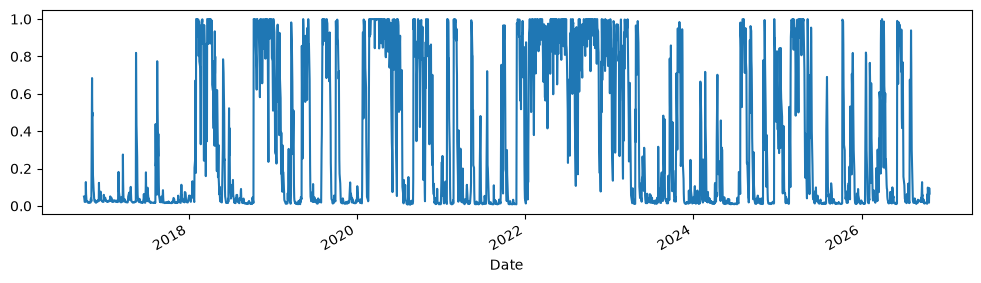

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

features["markov_switching_probability"].plot(figsize=(12, 3))
plt.show()

In [ ]:
features.dropna().to_parquet("features.parquet")

## Stats

In [ ]:
from scipy.stats import ks_2samp
import pandas as pd
K = 10
spy = close["SPY"]

rows = []
for x in (0.03, 0.04, 0.05, 0.06, 0.08):
    yy = part_one.make_labels(spy, k=K, mode="fixed", fixed=x).loc[part_one.ANALYSIS_START:]
    ep = part_one.episodes(yy, spy.loc[yy.index], k=K, gap=K)
    rows.append(dict(x=x, pos_rate=round(yy.mean(), 4), positive_days=int(yy.sum()),
                     episodes=len(ep), n_obs=int(yy.notna().sum())))
print(pd.DataFrame(rows).to_string(index=False))

   x  pos_rate  positive_days  episodes  n_obs
0.03    0.1790            451        34   2519
0.04    0.1139            287        29   2519
0.05    0.0742            187        22   2519
0.06    0.0500            126        18   2519
0.08    0.0242             61         8   2519


fixing a value of drawdown and observing the portions that are going to be labelled as crash in that case

In [ ]:
X = 0.08    # set from the table above

y = part_one.make_labels(spy, k=K, mode="fixed", fixed=X).rename("y")
df = features.join(y).dropna()          # drops the last K rows (NaN labels)

print(df.shape, df.index.min().date(), df.index.max().date())
print(df["y"].value_counts())
print("base rate:", round(df["y"].mean(), 4))
print(df.head())

print(df.groupby(df.index.year)["y"].agg(positives="sum", days="count", rate="mean").round(3))

print(part_one.episodes(df["y"], spy.loc[df.index], k=K, gap=K))

(2519, 7) 2016-10-03 2026-10-09
y
0.0    2458
1.0      61
Name: count, dtype: int64
base rate: 0.0242
            markov_switching_probability  volatility_term_structure  \
Date                                                                  
2016-10-03                      0.050009                   0.827439   
2016-10-04                      0.044524                   0.827565   
2016-10-05                      0.030713                   0.800863   
2016-10-06                      0.021562                   0.799004   
2016-10-07                      0.022127                   0.819951   

            credit_appetite_change  real_yield_change  \
Date                                                    
2016-10-03                0.007729              -0.12   
2016-10-04                0.012992              -0.13   
2016-10-05                0.018098               0.01   
2016-10-06                0.013373               0.07   
2016-10-07                0.015400               0.02   



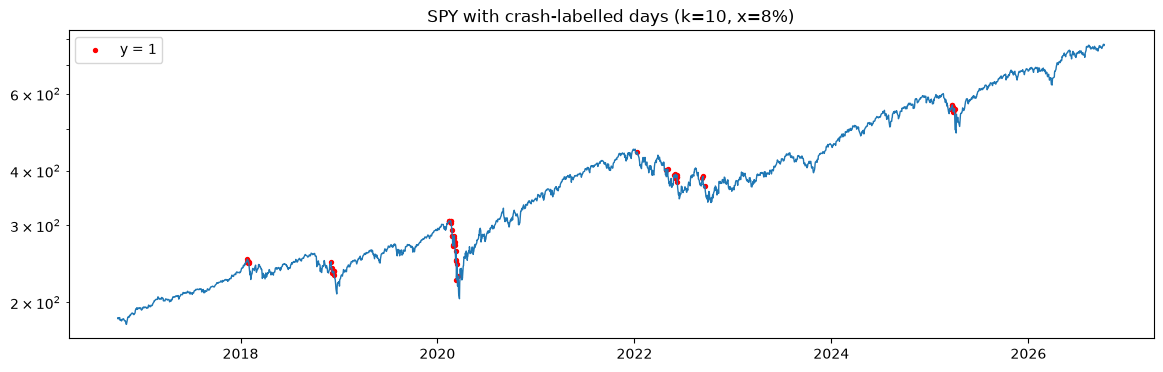

In [ ]:
px = spy.loc[df.index]
flag = df["y"] == 1
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(px.index, px, lw=1)
ax.scatter(px.index[flag], px[flag], s=8, color="red", label="y = 1")
ax.set_yscale("log"); ax.legend(); ax.set_title(f"SPY with crash-labelled days (k={K}, x={X:.0%})")
plt.show()

KS Test (seeing if the feature values in a determined upcoming crash (1) and calm (0) are coming from the same distribution)

In [ ]:
summary = df.groupby("y")[list(features.columns)].median().T
summary["ks_stat"] = [ks_2samp(df.loc[df.y == 1, c], df.loc[df.y == 0, c]).statistic
                      for c in features.columns]
print(summary.round(3))

y                               0.0    1.0  ks_stat
markov_switching_probability  0.075  0.902    0.457
volatility_term_structure     0.876  0.947    0.534
credit_appetite_change        0.003 -0.008    0.336
real_yield_change             0.010 -0.060    0.179
average_pairwise_correlation  0.056 -0.040    0.379
yield_curve_slope_change     -0.010  0.030    0.155


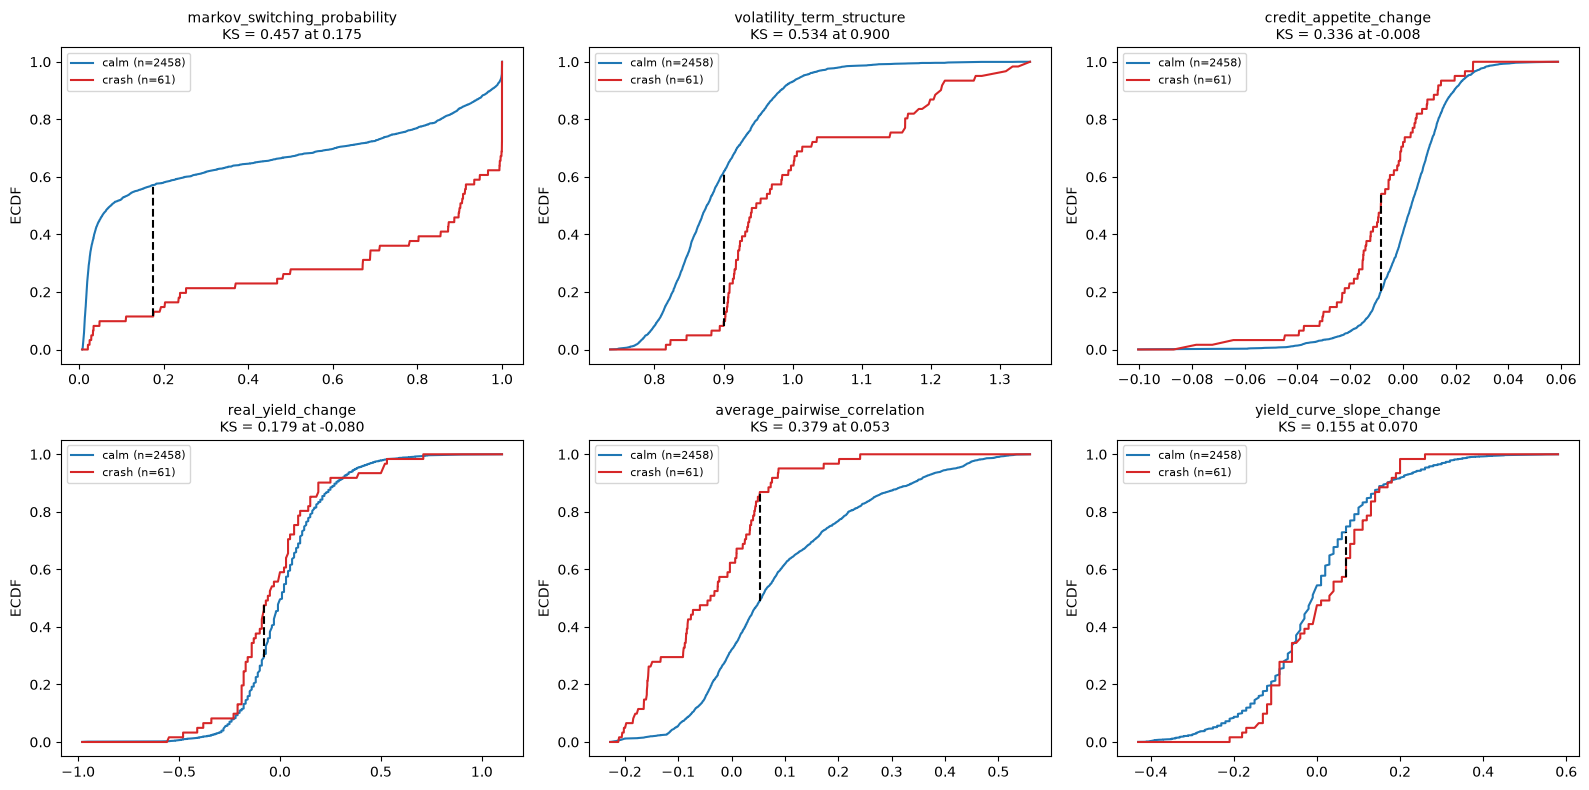

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

cols = list(features.columns)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, c in zip(axes.ravel(), cols):
    a = np.sort(df.loc[df.y == 0, c].values)      # calm
    b = np.sort(df.loc[df.y == 1, c].values)      # crash-labelled
    grid = np.sort(np.concatenate([a, b]))
    Fa = np.searchsorted(a, grid, side="right") / len(a)
    Fb = np.searchsorted(b, grid, side="right") / len(b)
    gap = np.abs(Fa - Fb)
    i = gap.argmax()

    ax.plot(grid, Fa, label=f"calm (n={len(a)})", color="tab:blue")
    ax.plot(grid, Fb, label=f"crash (n={len(b)})", color="tab:red")
    ax.vlines(grid[i], min(Fa[i], Fb[i]), max(Fa[i], Fb[i]), color="k", ls="--")
    ax.set_title(f"{c}\nKS = {ks_2samp(a, b).statistic:.3f} at {grid[i]:.3f}", fontsize=10)
    ax.set_ylabel("ECDF")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

as we can see, the features real_yield_change and yield_curve_slope_change are having the same distributions for both crashes and calm days, this means, just be looking at the feature values it is difficult to say whether the day is tending to a coming crash or not. we still wont remove it because maybe it is useful as a combination with the other features

## Model Running

In [ ]:
from scipy.optimize import minimize
from scipy.stats import rankdata

# ---------- metrics (replace sklearn.metrics) ----------
def auc_score(y, p):
    y = np.asarray(y); r = rankdata(p)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def pr_auc(y, p):                      # average precision
    y = np.asarray(y); o = np.argsort(-np.asarray(p)); yy = y[o]
    prec = np.cumsum(yy) / np.arange(1, len(yy) + 1)
    return (prec * yy).sum() / yy.sum()

def brier(y, p):
    return float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))

# ---------- models (replace sklearn.linear_model / dummy) ----------
class Prior:                           # rung 0: always the training base rate
    def fit(self, X, y): self.p = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.p)

class Logit:                           # L2 logistic regression, balanced class weights
    def __init__(self, l2=1.0): self.l2 = l2
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-9
        Z = (X - self.mu) / self.sd
        n, n1 = len(y), y.sum(); n0 = n - n1
        w = np.where(y == 1, n / (2 * n1), n / (2 * n0))
        def f(b):
            z = Z @ b[1:] + b[0]
            p = 1 / (1 + np.exp(-z))
            loss = (w * (np.logaddexp(0, z) - y * z)).sum() + 0.5 * self.l2 * (b[1:] ** 2).sum()
            g = w * (p - y)
            return loss, np.r_[g.sum(), Z.T @ g + self.l2 * b[1:]]
        self.b = minimize(f, np.zeros(Z.shape[1] + 1), jac=True, method="L-BFGS-B").x
        return self
    def predict(self, X):
        Z = (np.asarray(X, float) - self.mu) / self.sd
        return 1 / (1 + np.exp(-(Z @ self.b[1:] + self.b[0])))

# ---------- data ----------
vol20 = np.log(spy).diff().rolling(20).std().rename("vol20")
data = df.join(vol20).dropna()
six = list(features.columns)

def walk_forward(data, cols, model_fn, min_train=756, step=252, purge=K):
    preds = pd.Series(np.nan, index=data.index)
    for t0 in range(min_train, len(data), step):
        tr = data.iloc[: t0 - purge]
        te = data.iloc[t0: t0 + step]
        if tr["y"].nunique() < 2 or len(te) == 0:
            continue
        preds.iloc[t0: t0 + step] = model_fn().fit(tr[cols].values, tr["y"].values).predict(te[cols].values)
    return preds

runs = {
    "0 base rate":    (["vol20"], Prior),
    "2 all features": (six, Logit),
}
for c in six:
    runs[f"drop {c}"] = ([f for f in six if f != c], Logit)

preds = {name: walk_forward(data, cols, fn) for name, (cols, fn) in runs.items()}

common = pd.concat(preds.values(), axis=1).notna().all(axis=1)
yt = data.loc[common, "y"]
print(f"scored rows: {common.sum()}, positives: {int(yt.sum())}, base rate: {yt.mean():.4f}")

res = pd.DataFrame([dict(model=n, auc=auc_score(yt, p[common]),
                         pr_auc=pr_auc(yt, p[common]), brier=brier(yt, p[common]))
                    for n, p in preds.items()]).set_index("model")
res["d_auc_vs_all"] = res["auc"] - res.loc["2 all features", "auc"]
print(res.round(4).to_string())

yrs = data.loc[common].index.year
def yr_auc(name, y_):
    m = yrs == y_
    return auc_score(yt[m], preds[name][common][m]) if yt[m].nunique() == 2 else np.nan
per_year = pd.DataFrame({"positives": yt.groupby(yrs).sum(), "days": yt.groupby(yrs).size()})
per_year["auc_all"] = [yr_auc("2 all features", y_) for y_ in per_year.index]
print(per_year.round(3).to_string())

scored rows: 1763, positives: 47, base rate: 0.0267
                                      auc  pr_auc   brier  d_auc_vs_all
model                                                                  
0 base rate                        0.2283  0.0166  0.0263       -0.5554
2 all features                     0.7836  0.1160  0.0952        0.0000
drop markov_switching_probability  0.8147  0.1502  0.1067        0.0311
drop volatility_term_structure     0.7997  0.0678  0.0978        0.0160
drop credit_appetite_change        0.7986  0.1198  0.0994        0.0149
drop real_yield_change             0.7559  0.2298  0.0911       -0.0277
drop average_pairwise_correlation  0.6132  0.0621  0.1616       -0.1705
drop yield_curve_slope_change      0.8004  0.3308  0.0885        0.0167
      positives  days  auc_all
Date                                     
2019          0.0    61      NaN
2020         23.0   253    0.847
2021          0.0   252      NaN
2022         15.0   251    0.358
2023          0.0   250